# Fase 2 — Preprocesamiento, ingeniería y selección de variables
Este notebook **no reimplementa nada**: ejecuta y explica `src/preprocessing_pipeline.py`, que es el mismo código que usa
`predict.py`. Todo lo que se decide acá queda escrito en `data/processed/data_lineage.json`.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import auxiliar_functions as af
import preprocessing_pipeline as pp
SEMILLA = af.SEMILLA
pd.set_option("display.width", 200); sns.set_theme(style="whitegrid")
FIG = af.FIG_DIR
out = pp.run()
ds, sel, lineage, unified, qc = out["dataset"], out["seleccion"], out["lineage"], out["unified"], out["qc"]

Dataset final: data/processed/dataset_final.csv  (1164, 88)
Shapes: {'train': [815, 11], 'val': [174, 11], 'test': [175, 11]}
Variables seleccionadas: ['frio_hoy', 'frio_rm14', 'frio_delta1', 'frio_ult6h', 'doy_cos', 'frio_x_cos', 'envasado_ult6h', 'sala_maq_ult6h', 'pta_agua_eflu_rm7', 'kw_gral_planta_ult6h', 'frio_max7']


## 2.1 Limpieza de datos — decisiones
| Problema (detectado en la Fase 1) | Decisión | Por qué |
|---|---|---|
| Jornadas apiladas bajo una misma fecha (fin de meses cortos) | Se probó reasignarlas a las fechas faltantes (regla del EDA del equipo). **Por defecto se descartan** (`REASIGNAR_APILADAS = False`) | La validación por continuidad contradice la regla y la mejora en validación no es significativa (ver abajo) |
| Día que termina a las 23:00 (sin 23:59) | Se estima: 23:00 + ritmo de las últimas 3 h × 59 min | Validado en días sanos: MAE ~155 kW contra ~950 kW de usar las 23:00 |
| Día con < 24 lecturas o que arranca después de las 00:00 | Inválido | El último totalizador no es el consumo del día |
| Totalizador que no arranca en 0 a las 00:00 | Se conserva: el total de Frio es la suma de incrementos | El arrastre del día anterior no entra en la suma |
| Valores ≥ 1.000.000 | Frio: se reconstruye sacando el salto. Otras columnas: NaN | Físicamente imposibles; en Frio el resto del día es bueno |
| Saltos horarios del Frio (<0 o >3.000 kW en una hora) | ≤2 saltos: se reemplazan por la mediana horaria del día. >2: inválido | Validado inyectando saltos en días sanos y contra los casos reales que tienen su valor sano en otro archivo |
| Archivos solapados | Día válido > archivo más reciente | 488 de 493 fechas comparables coinciden exactamente |
| Fechas faltantes | Se reindexa a calendario completo **antes** del `shift(-1)` | Así D+1 es siempre el día calendario siguiente |
| Faltantes en features | Imputación por **mediana de train** dentro del Pipeline; los lags caen al último valor conocido | Robusto, sin mirar el futuro |
| Outliers extremos en features | Recorte a los cuantiles 0,5 %-99,5 % **aprendidos en train** (`QuantileClipper`) | Limita el efecto de lecturas raras sin borrar días reales (paradas de fin de año) |

In [2]:
motivos = qc[["incompleto", "imposible", "sin_reinicio", "apilado", "danado"]].groupby(level="archivo").sum()
print("Días marcados por archivo y motivo (un día puede tener más de un motivo):"); display(motivos)
# Conteos sobre el dataset final: un día por fecha, de la versión que ganó el desempate
v = unified[unified["_valido"]]
elegida = qc.loc[list(zip(v["_archivo"], v.index))].set_axis(v.index)
antes_ok = (qc.valido & ~qc.imposible & ~qc.estimado_2359 & ~qc.sin_reinicio).groupby(level="DIA").any()
recuperados = v.index[~antes_ok.reindex(v.index).fillna(False).to_numpy()]
print(f"Días del dataset final con algún salto corregido: {int((elegida.n_saltos > 0).sum())}")
print(f"Días recuperados que con las reglas anteriores no tenían ninguna versión válida: {len(recuperados)} "
      f"(imposibles: {int(elegida.loc[recuperados, 'imposible'].sum())}, "
      f"terminaban a las 23:00: {int(elegida.loc[recuperados, 'estimado_2359'].sum())}, "
      f"sin reinicio: {int(elegida.loc[recuperados, 'sin_reinicio'].sum())})")
print(f"Calendario unificado: {len(unified)} días | válidos: {unified['_valido'].sum()} | filas del dataset final: {len(ds)}")

Días marcados por archivo y motivo (un día puede tener más de un motivo):


,incompleto,imposible,sin_reinicio,apilado,danado
archivo,,,,,
Totalizadores Planta - 2021_2023.xlsx,5,0,1,8,1
Totalizadores Planta 2020_2022.xlsx,3,11,2,8,2
Totalizadores Planta 2022_2023.xlsx,5,0,0,6,0


Días del dataset final con algún salto corregido: 45
Días recuperados que con las reglas anteriores no tenían ninguna versión válida: 6 (imposibles: 3, terminaban a las 23:00: 1, sin reinicio: 2)
Calendario unificado: 1213 días | válidos: 1165 | filas del dataset final: 1164


Los días de parada de fin de año (Frio de 2.000-5.000 kW) **no** se eliminan: son reales y el modelo tiene que saber que existen.
Las filas del dataset final son los días D con target conocido (D+1 válido) y con algún nivel reciente de Frio.

## Validación de los métodos de recuperación
Cada recuperación de datos se prueba contra un valor real antes de usarla.

### 1. Estimar las 23:59 desde las 23:00
En los días sanos (25 lecturas, arranque en 0, sin saltos) conocemos el valor real de las 23:59, así que podemos fingir que falta y medir el error de cada método.

In [3]:
sanos = []
for f in af.find_excels():
    ee = af.read_excel_sheets(f, [af.TARGET_SHEET])[af.TARGET_SHEET]
    h = af.prepare_hourly(ee, af.TARGET_SHEET, reasignar=False)
    s = af.dias_sanos(h, af.TARGET_RAW_COL); s["archivo"] = f.name; sanos.append((f.name, h, s))
P = pd.concat([s for _, _, s in sanos]); P = P[~P.index.duplicated()].drop(columns="archivo")
print(f"Días sanos con el valor real: {len(P)}")
af.validar_estimacion_2359(P).round(1)

Días sanos con el valor real: 1129


,MAE_kW,sesgo_kW
23:00 sin corregir,949.1,-949.1
ritmo últimas 3 h (elegido),154.6,31.7
ritmo últimas 6 h,156.6,42.8
ritmo del día completo,170.7,14.1


Usar las 23:00 tal cual subestima ~950 kW. Extrapolar con el ritmo de las últimas horas baja el error a ~155 kW. Elegimos **3 horas**:
error mínimo, sesgo chico y no aprende ningún parámetro de los datos. El ritmo del día completo tiene menos sesgo, pero más error.

### 2. Reconstruir saltos y totales imposibles de Frio
**(a) Sintético:** en cada día sano se inyecta un salto (de 25 mil, 1 millón o 5 millones de kW) en una hora al azar y se aplica la corrección.
**(b) Real:** los días imposibles del archivo `2020_2022` tienen su valor sano en `2021_2023`, así que la reconstrucción se compara con un dato real.

In [4]:
print("Sintético:", {k: round(v, 1) if isinstance(v, float) else v for k, v in af.validar_reconstruccion_saltos(P).items()})
archivos = qc.index.get_level_values("archivo").unique()
qa = qc.xs(next(a for a in archivos if "2020_2022" in a), level="archivo")
qb = qc.xs(next(a for a in archivos if "2021_2023" in a), level="archivo")
casos = qa[qa.imposible & qa.valido].index.intersection(qb[(qb.n_saltos == 0) & qb.valido].index)
real = pd.DataFrame({"total crudo 23:59": qa.loc[casos, "valor_2359"],
                     "reconstruido": qa.loc[casos, "valor_corregido"].round(0),
                     "valor sano (otro archivo)": qb.loc[casos, "valor_2359"]})
real["error"] = (real["reconstruido"] - real["valor sano (otro archivo)"]).round(0)
display(real)
print(f"MAE en casos reales: {real.error.abs().mean():,.0f} kW")

Sintético: {'dias': 1129, 'MAE_kW': 162.7, 'sesgo_kW': -10.5}


,total crudo 23:59,reconstruido,valor sano (otro archivo),error
DIA,,,,
2021-07-28,2900770.0,31041.0,30764.0,277.0
2021-08-25,2907122.0,37127.0,37122.0,5.0
2021-09-08,38303.0,38078.0,38303.0,-225.0
2021-11-17,16918.0,16479.0,16918.0,-439.0
2021-11-28,6155928.0,25347.0,25719.0,-372.0
2022-01-12,13445.0,13968.0,13445.0,523.0
2022-02-18,8861470.0,21182.0,21470.0,-288.0
2022-02-24,18939.0,18806.0,18939.0,-133.0


MAE en casos reales: 283 kW


La reconstrucción también recupera el único imposible de Frio sin respaldo en otro archivo: el bloque apilado del 30/04/2021, que con
la regla de reasignación cae en el 31/03/2021, se reconstruye a 32.654 kW. En el dataset por defecto ese bloque no se usa (ver abajo).

### 3. Jornadas apiladas: ¿se pueden reasignar a las fechas faltantes?
Las fechas faltantes de cada archivo coinciden exactamente con la cantidad de bloques sobrantes, y la regla del EDA del equipo los reasigna
(30/MM → 31/(MM-1); fin de febrero → 31/12, 30/08 y 29/08 del año anterior). Lo verificamos con un criterio independiente:
¿el total del bloque se parece a los días vecinos de su **fecha destino** o a los de su **fecha original**?

In [5]:
filas = []
for nombre, h, _ in sanos:
    tot = h[(h.bloque == 0) & (h.MIN == af.END_OF_DAY_MIN)].groupby("DIA")[af.TARGET_RAW_COL].first()
    tot = tot[tot < af.VALOR_IMPOSIBLE]
    vecinos = lambda d: np.nanmean([tot.get(d + pd.Timedelta(days=k), np.nan) for k in (-2, -1, 1, 2)])
    for (d, b), g in h[h.bloque > 0].groupby(["DIA", "bloque"]):
        v = g.loc[g.MIN == af.END_OF_DAY_MIN, af.TARGET_RAW_COL]
        dest = af.destinos_apilados(d, int(b))
        if not len(v) or v.iloc[0] >= af.VALOR_IMPOSIBLE or dest is None:
            continue
        filas.append({"origen": d.date(), "bloque": b, "destino": dest.date(), "total": v.iloc[0],
                      "error_vs_destino": abs(v.iloc[0] - vecinos(dest)), "error_vs_origen": abs(v.iloc[0] - vecinos(d))})
cont = pd.DataFrame(filas).drop_duplicates(["destino", "total"])
display(cont.round(0))
ref = np.nanmedian([abs(tot[d] - vecinos(d)) for d in tot.index[5:-5]])
print(f"Mediana |total - vecinos|: destino {cont.error_vs_destino.median():,.0f} kW | origen {cont.error_vs_origen.median():,.0f} kW "
      f"| un día normal {ref:,.0f} kW | el destino gana en {(cont.error_vs_destino < cont.error_vs_origen).sum()} de {len(cont)}")

,origen,bloque,destino,total,error_vs_destino,error_vs_origen
0,2021-09-30,1,2021-08-31,22364.0,12187.0,3295.0
1,2021-11-30,1,2021-10-31,11561.0,1511.0,4574.0
2,2022-02-28,1,2021-12-31,21088.0,18215.0,1657.0
3,2022-02-28,2,2021-08-30,20959.0,15654.0,1786.0
4,2022-02-28,3,2021-08-29,16363.0,17742.0,6382.0
5,2022-04-30,1,2022-03-31,24659.0,5867.0,5406.0
6,2022-06-30,1,2022-05-31,26448.0,7130.0,308.0
7,2022-09-30,1,2022-08-31,20598.0,3715.0,70.0
8,2022-11-30,1,2022-10-31,17252.0,2999.0,626.0
9,2023-02-28,1,2022-12-31,20857.0,11524.0,1570.0


Mediana |total - vecinos|: destino 4,983 kW | origen 2,154 kW | un día normal 2,202 kW | el destino gana en 6 de 21


Los bloques se parecen a los vecinos de su fecha **original** tanto como un día normal, y no a los de la fecha destino. El caso más claro
son los bloques de ~21.000 kW mandados al 31/12, que es una parada de fin de año (vecinos de ~3.000 kW). Probamos además el efecto en el
modelo, comparando sobre las **mismas fechas de validación**:

In [6]:
import auxiliar_functions as _af
_af.REASIGNAR_APILADAS = True
out_r = pp.run(verbose=False, guardar=False)
_af.REASIGNAR_APILADAS = False
import train_model as tm
comunes = ds[ds.split == "val"].index.intersection(out_r["dataset"].query("split == 'val'").index)
# conjunto reducido de referencia: Frio, tres áreas y producción, sin el fin de día de las otras áreas
V10 = ["frio_hoy", "frio_rm7", "frio_rm14", "frio_delta1", "frio_ult6h", "frio_ult12h", "doy_cos",
       "elaboracion", "sala_maq", "envasado", "frio_x_cos", "mosto_x_cos"]
filas = []
for etiqueta, d, feats in [("descartar apiladas · conjunto reducido (12 variables, 2 hojas)", ds, V10),
                           ("descartar apiladas · selección final", ds, sel["seleccionadas"]),
                           ("reasignar apiladas · selección propia", out_r["dataset"], out_r["seleccion"]["seleccionadas"])]:
    tr_ = d[d.split == "train"]
    for a in (30, 100, 300):
        m = tm.make_model("Lasso", {"alpha": a, "max_iter": 50000}, "nivel").fit(tr_[feats], tr_.y)
        p = pd.Series(m.predict(d.loc[comunes, feats]), index=comunes)
        filas.append({"variante": etiqueta, "alpha": a, "MAE_val_kW": float((p - d.loc[comunes, "y"]).abs().mean())})
comp = pd.DataFrame(filas).sort_values("MAE_val_kW").groupby("variante").first().sort_values("MAE_val_kW")
display(comp.round(1))

,alpha,MAE_val_kW
variante,,
reasignar apiladas · selección propia,300,2079.8
descartar apiladas · selección final,300,2103.3
"descartar apiladas · conjunto reducido (12 variables, 2 hojas)",100,2124.4


Reasignar mejora unas decenas de kW en validación, una diferencia del orden del error estándar de una comparación pareada (~30 kW) y lejos
del umbral de 300 kW. Frente a una validación por continuidad que dice que la mayoría de los bloques no corresponde a su fecha destino,
**no alcanza para meter esos datos**: un 31/12 con 21.000 kW contamina los lags y el target de los días de parada. Queda como opción
(`REASIGNAR_APILADAS = True` en `auxiliar_functions.py`) y la decisión está documentada en el linaje.

## 2.2 Feature engineering
| Grupo | Variables | Justificación |
|---|---|---|
| Nivel y lags | `frio_hoy`, `frio_lag1/2/7`, `frio_delta1` | El consumo tiene mucha inercia (r=0,85 entre días consecutivos) |
| Medias móviles | `frio_rm3/7/14/28`, `frio_std7` | Suavizan el ruido diario y capturan la tendencia estacional reciente |
| Ritmo de fin de día | `frio_ult6h`, `frio_ult12h` (llevados a 24 h) | Cómo termina el día D es lo más cercano al arranque de D+1 |
| Calendario | `doy_sin`, `doy_cos`; `mes`, `dia_semana`, `fin_de_semana` **del día D+1** | Codificación cíclica; la fecha de mañana se conoce de antemano |
| Áreas de la planta (todas las de *Consolidado EE*) | para cada columna `x`: `x` (total), `x_ult6h` (18:00 → cierre), `x_rm7` (media 7 d); más `condensadores` | Cómo trabajó y **cómo terminó** el día el resto de la planta |
| Extremos recientes | `frio_min7`, `frio_max7` | Rango de la última semana |
| Producción | `hl_mosto`, `hl_mosto_rm7`, `hl_bodega`, `hl_envasada`, `hl_filtrada` | Más mosto = más calor de fermentación en los días siguientes |
| Otros servicios | `agua_planta`, `aire_producido` | Agua de condensadores evaporativos ~ carga térmica |
| Ratios | `ratio_frio_planta`, `ratio_frio_elab` | Peso relativo del frío en la planta |
| Eficiencia | `eficiencia_frio` = (EE Frio / Hl) / Meta EE Frio | Consumo real contra meta (hoja *Consolidado KPI*) |
| Interacciones | `frio_x_cos`, `mosto_x_cos` | El mismo nivel/producción pesa distinto en verano que en invierno |

Todas usan **solo información disponible al cierre del día D**. Las medias móviles y lags miran hacia atrás.

Features construidas: 86 | candidatas (sin las descartadas por EDA): 84


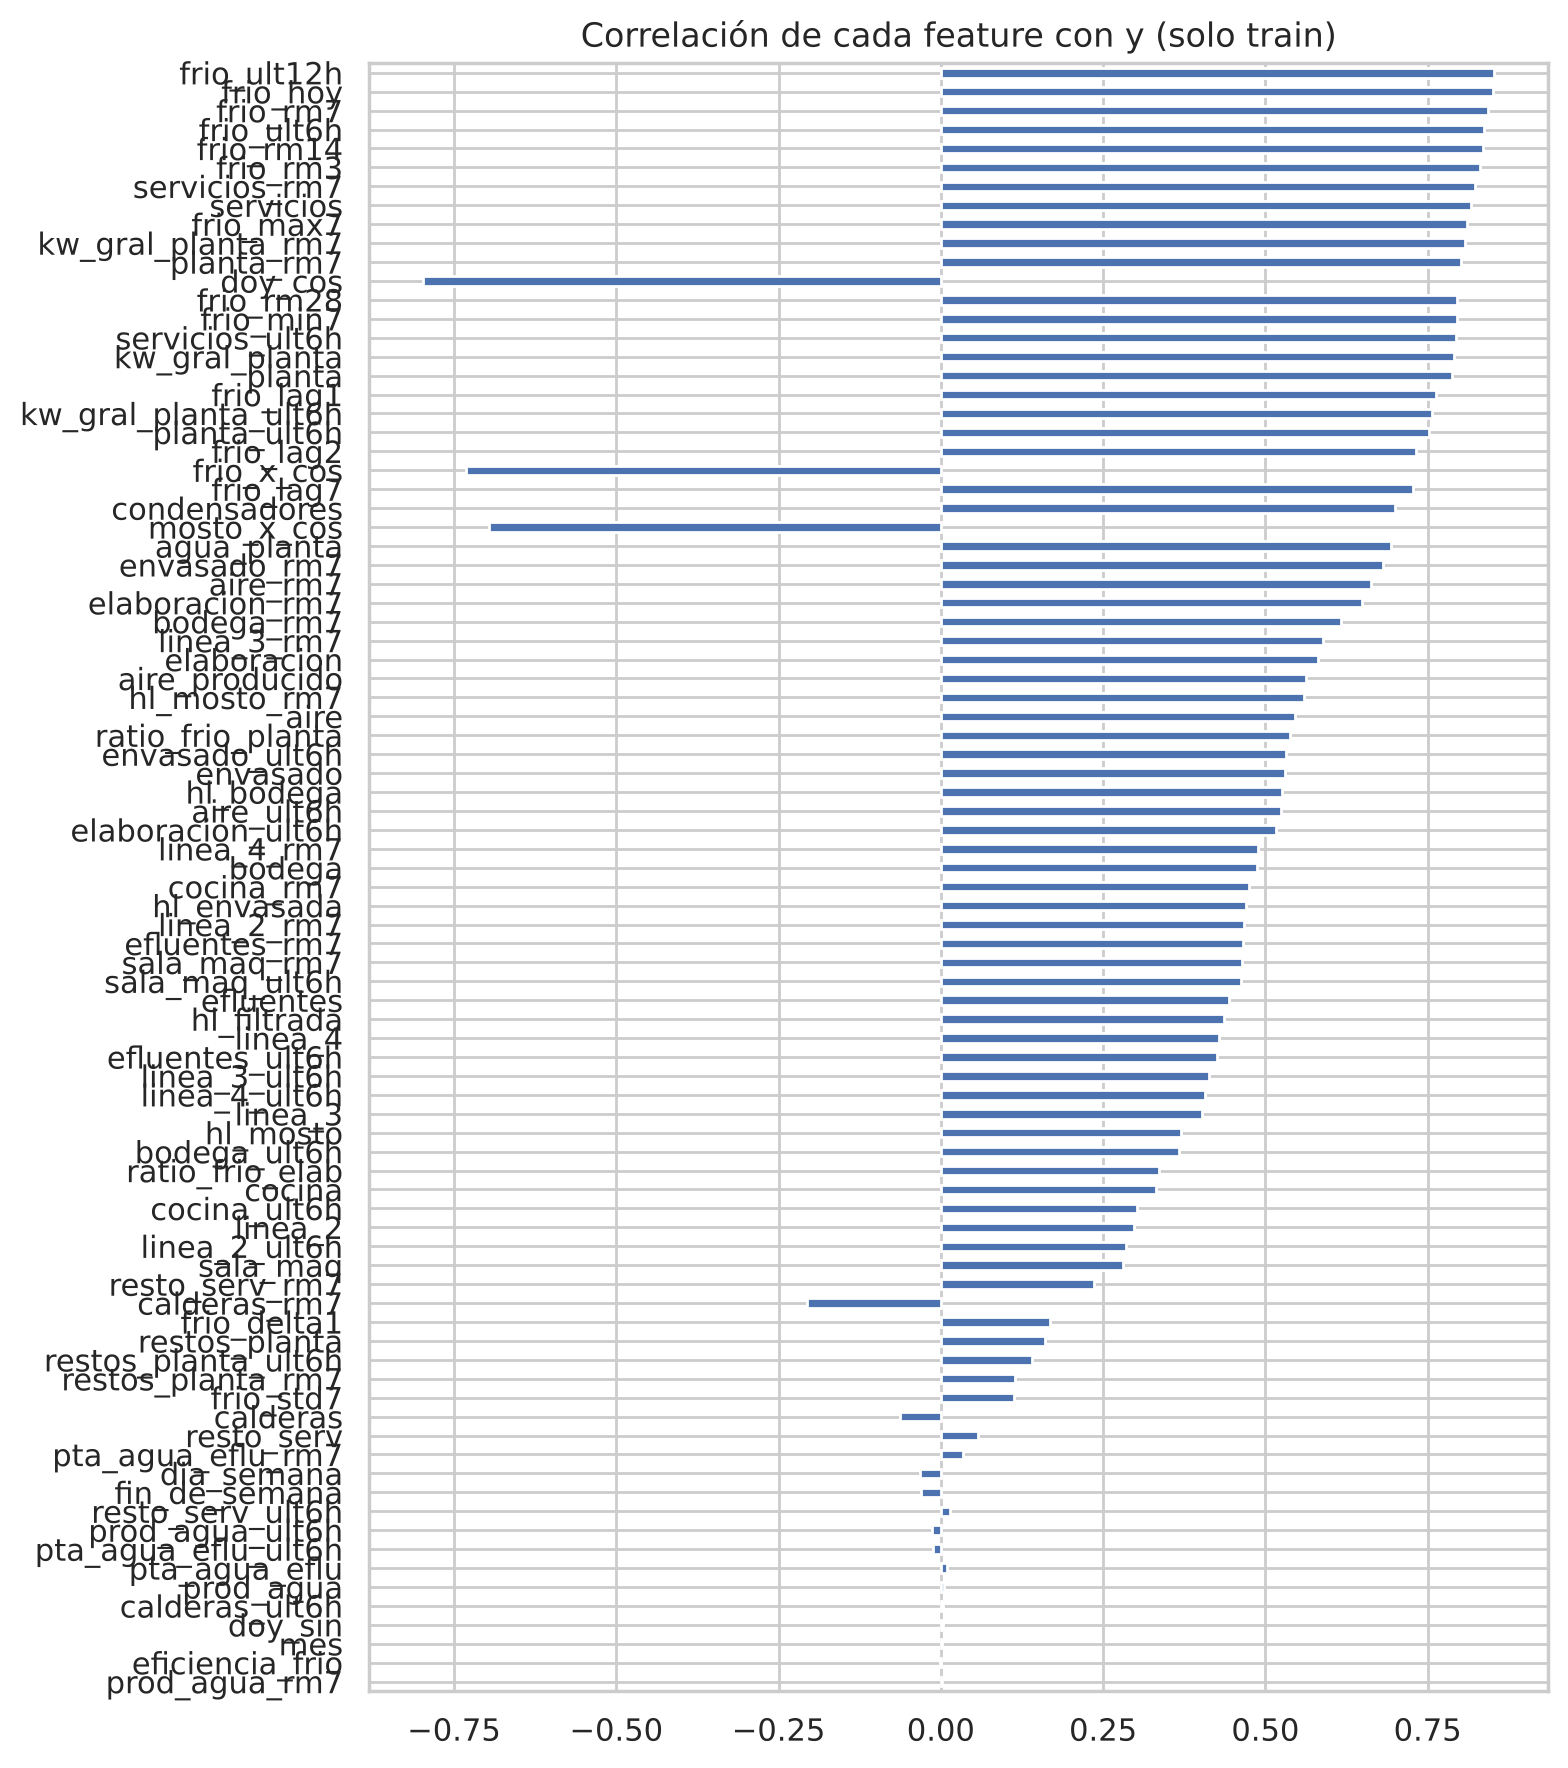

In [7]:
feats_all = list(pp.FEATURE_DEPS)
print(f"Features construidas: {len(feats_all)} | candidatas (sin las descartadas por EDA): {len(pp.CANDIDATAS)}")
tr = ds[ds.split == "train"]
c = tr[feats_all].corrwith(tr[pp.TARGET_Y]).sort_values(key=abs, ascending=False)
ax = c.plot.barh(figsize=(8, 9), title="Correlación de cada feature con y (solo train)"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG / "corr_features_train.png", dpi=120); plt.show()

### Verificación: ¿el día de la semana aporta algo al modelo?

In [8]:
va = ds[ds.split == "val"]
dow = lambda d: pd.get_dummies(d["dia_semana"], prefix="dow", dtype=float)
trx, vax = tr.join(dow(tr)), va.join(dow(va))
dcols = [c for c in trx.columns if c.startswith("dow_")]
base = sel["seleccionadas"]
res = {}
for nombre, cols in {"seleccionadas": base, "+ dia_semana (one-hot)": base + dcols, "+ fin_de_semana": base + ["fin_de_semana"]}.items():
    m = Pipeline([("pre", pp.make_preprocessor()), ("m", Lasso(alpha=100, max_iter=50000))]).fit(trx[cols], trx.y)
    res[nombre] = np.mean(np.abs(m.predict(vax[cols]) - vax.y))
pd.Series(res, name="MAE validación (kW)").round(1).to_frame()

,MAE validación (kW)
seleccionadas,2113.3
+ dia_semana (one-hot),2154.1
+ fin_de_semana,2113.3


Agregar el día de la semana **no mejora** el MAE de validación (lo empeora con one-hot): se confirma el descarte del EDA.

## 2.3 Selección de variables (solo con train)
Tres métodos independientes, ajustados sobre el tramo de entrenamiento:
1. **LASSO** con `alpha` elegido por `TimeSeriesSplit` (5 folds): se queda con coeficientes ≠ 0.
2. **Importancia de Random Forest** (500 árboles, `random_state=42`): top 15.
3. **RFE con Ridge**: 15 variables.

Antes, un filtro que no mira el target: fuera las candidatas con más de 5 % de faltantes o 10 valores distintos o menos en train.

Regla final: entra la variable elegida por **al menos 2 de los 3** métodos.

In [9]:
votos = sel["votos"].astype(int).sort_values(["votos", "lasso", "random_forest"], ascending=False)
display(votos.style.background_gradient(subset=["votos"], cmap="Greens"))
print("Seleccionadas:", sel["seleccionadas"])

,lasso,random_forest,rfe_ridge,votos
frio_rm14,1,1,1,3
frio_ult6h,1,1,1,3
doy_cos,1,1,1,3
frio_hoy,1,1,0,2
sala_maq_ult6h,1,1,0,2
frio_max7,1,1,0,2
frio_delta1,1,0,1,2
envasado_ult6h,1,0,1,2
pta_agua_eflu_rm7,1,0,1,2
kw_gral_planta_ult6h,1,0,1,2


Seleccionadas: ['frio_hoy', 'frio_rm14', 'frio_delta1', 'frio_ult6h', 'doy_cos', 'frio_x_cos', 'envasado_ult6h', 'sala_maq_ult6h', 'pta_agua_eflu_rm7', 'kw_gral_planta_ult6h', 'frio_max7']


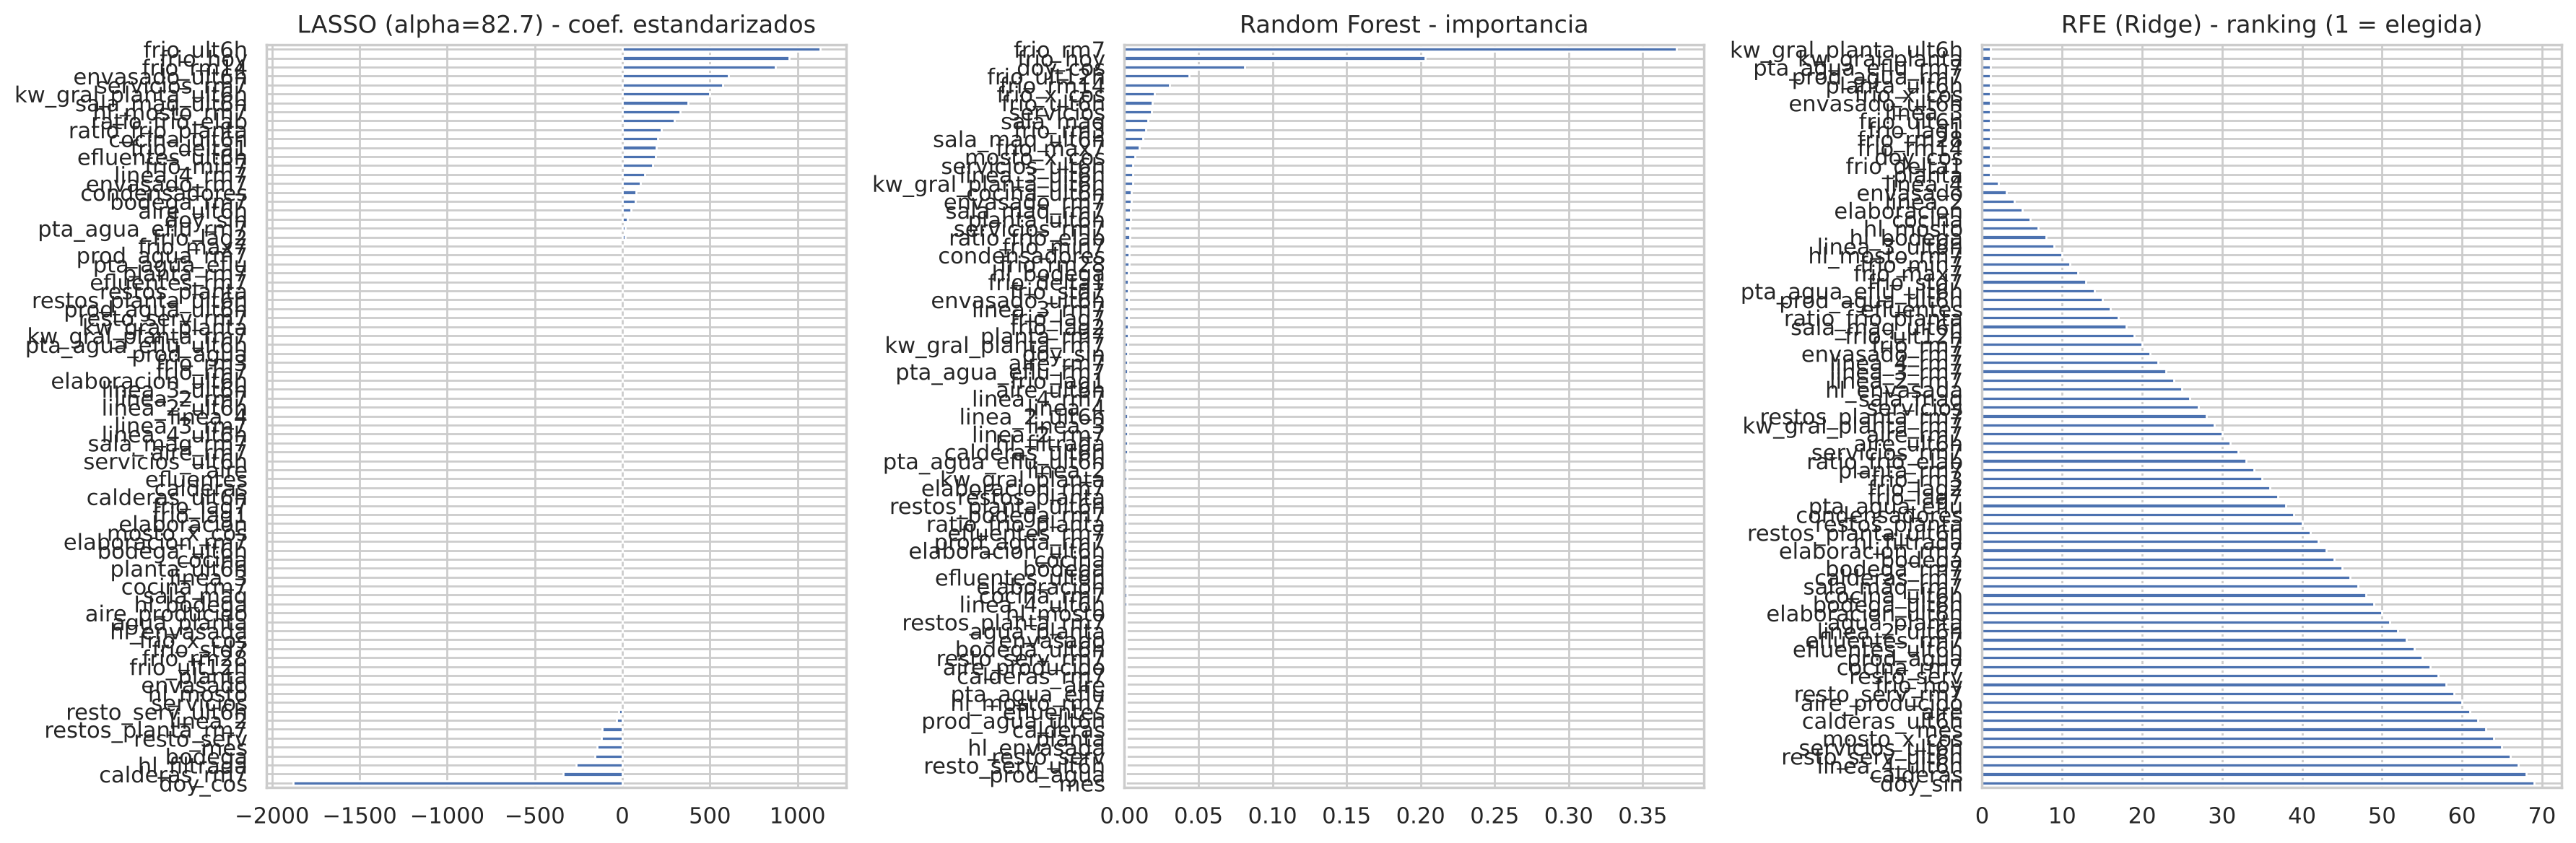

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
sel["lasso_coef"].sort_values().plot.barh(ax=ax[0], title=f"LASSO (alpha={sel['lasso_alpha']:.1f}) - coef. estandarizados")
sel["rf_importancia"].sort_values().plot.barh(ax=ax[1], title="Random Forest - importancia")
sel["rfe_ranking"].sort_values(ascending=False).plot.barh(ax=ax[2], title="RFE (Ridge) - ranking (1 = elegida)")
plt.tight_layout(); plt.savefig(FIG / "seleccion_variables.png", dpi=120); plt.show()

**Justificación del conjunto final.** Sobreviven: el nivel actual, la media de 14 días y el máximo de la semana (inercia y tendencia),
el cambio del último día, la estación (`doy_cos` y su interacción con el nivel) y, sobre todo, **cómo terminó el día**: el consumo de
las últimas 6 horas del frío, de la planta completa (`kw_gral_planta_ult6h`, que es la misma medición que `planta_ult6h`: correlación
1,000), de Sala de Máquinas y de Envasado. Quedan afuera los lags largos (redundantes), las variables de producción, agua y aire, y los
ratios/eficiencia. **Todas las variables salen de una sola hoja** (*Consolidado EE*), lo que achica el contrato de `predict.py`.

## 2.4 Preparación y versionado de los datos procesados

In [11]:
print(json.dumps({k: lineage[k] for k in ("generado", "script", "entradas", "dias_calendario", "dias_validos",
                                           "filas_dataset_final", "shapes", "rangos")}, indent=2, ensure_ascii=False))
print("\nPasos registrados en el linaje:"); [print(" -", p) for p in lineage["pasos"]]
print("\nchecksums.json:"); print(json.dumps(json.loads((af.DATA_DIR / "checksums.json").read_text()), indent=2))

{
  "generado": "2026-11-24T04:05:17+00:00",
  "script": "src/preprocessing_pipeline.py",
  "entradas": [
    "Totalizadores Planta - 2021_2023.xlsx",
    "Totalizadores Planta 2020_2022.xlsx",
    "Totalizadores Planta 2022_2023.xlsx"
  ],
  "dias_calendario": 1213,
  "dias_validos": 1165,
  "filas_dataset_final": 1164,
  "shapes": {
    "train": [
      815,
      11
    ],
    "val": [
      174,
      11
    ],
    "test": [
      175,
      11
    ]
  },
  "rangos": {
    "train": [
      "2020-07-01",
      "2022-10-25"
    ],
    "val": [
      "2022-10-26",
      "2023-04-25"
    ],
    "test": [
      "2023-04-26",
      "2023-10-24"
    ]
  }
}

Pasos registrados en el linaje:
 - lectura por nombre de hojas/columnas; HORA truncada al minuto
 - jornadas apiladas: fechas invalidas (la regla de reasignacion no paso la validacion)
 - total diario = lectura de las 23:59; si falta, 23:00 + ritmo de las ultimas 3 h x 59 min
 - Frio: total = suma de incrementos horarios; saltos (<0 o

In [12]:
for s in ("train", "val", "test"):
    X = ds.loc[ds.split == s, sel["seleccionadas"]]
    print(f"X_{s:5s} shape={X.shape}  {X.index.min().date()} -> {X.index.max().date()}")
print("\ndataset_final.csv está SIN escalar (medias en kW, no ~0):")
ds[sel["seleccionadas"]].describe().T[["mean", "std", "min", "max"]].round(1)

X_train shape=(815, 11)  2020-07-01 -> 2022-10-25
X_val   shape=(174, 11)  2022-10-26 -> 2023-04-25
X_test  shape=(175, 11)  2023-04-26 -> 2023-10-24

dataset_final.csv está SIN escalar (medias en kW, no ~0):


,mean,std,min,max
frio_hoy,23546.7,7596.6,2310.0,48046.0
frio_rm14,23601.7,6639.4,7757.9,36900.8
frio_delta1,52.4,3954.4,-14844.0,17881.0
frio_ult6h,24043.1,8189.7,0.0,47576.0
doy_cos,-0.0,0.7,-1.0,1.0
frio_x_cos,-4972.7,16686.7,-47388.9,22280.8
envasado_ult6h,3444.8,1654.9,78.0,7667.0
sala_maq_ult6h,6710.5,3654.0,-59272.0,35730.0
pta_agua_eflu_rm7,1421.4,2847.6,-40208.7,34639.0
kw_gral_planta_ult6h,16520.9,4593.2,0.0,47032.0


In [13]:
pp.make_preprocessor()  # este Pipeline se ajusta SOLO con train, dentro del modelo (ver modelado.ipynb)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('clip', ...), ('imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,low,0.005
,high,0.995
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predict

**Partición temporal:** 70 % más antiguo para train, 15 % validación, 15 % más reciente para test. La selección de variables
usó solo train. El escalado y la imputación viven dentro del `Pipeline` del modelo, así que el CSV versionado no contiene
ninguna estadística calculada con validación o test.